In [1]:
from os.path import dirname, abspath, join, exists
import sys
import numpy as np
import pandas as pd
import json
from omegaconf import OmegaConf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable
from typing import List
import re, os, json
from os import makedirs
from torchmetrics.regression import R2Score, MeanSquaredError, MeanAbsoluteError

root_path = dirname(abspath("./"))
import sys
sys.path.append(root_path)
from proT.evaluation.predict import *
from proT.evaluation.metrics import compute_prediction_metrics
from notebooks.lib import plot_predictions_enhanced, plot_predictions, plot_predictions_adaptive


# plotting standard settings
plt.rcParams['figure.dpi'] = 100 #360 # standard is 360 but for set to 100 for practical visualization on the notebook
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.figsize'] = (6, 6)
plt.rcParams['lines.linewidth'] = 1.5
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=sns.color_palette('colorblind'))
plt.rcParams['lines.linewidth'] = 2.0

datadir_path    = r"../data/input"
output_dir      = "./output"
save_dir        = "./figures"
makedirs(output_dir, exist_ok=True)
makedirs(save_dir, exist_ok=True)

S6 Mamba backend: mamba-pytorch (pure PyTorch fallback)


# Lib

Predictions are cached in `./output/case_study_*.npz`. If a cache file exists it is
loaded instead of re-running the model. Delete the file to force re-prediction.

In [2]:
def get_config_and_best_checkpoint(exp_path):
    
    # get config
    config_regex = re.compile("config")
    best_trial_regex = re.compile("best_trial")
    
    config_list = []
    summary_list = []
    for file in os.listdir(exp_path):
        
        if config_regex.match(file):
            config_list.append(file)
                
        elif best_trial_regex.match(file):
            summary_list.append(file)
    
    if len(config_list) != 1:
        raise ValueError(f"More (or none) than one config found! {config_list}")
    else:
        config = OmegaConf.load(os.path.join(exp_path, config_list[0]))
    if len(summary_list) != 1:
        raise ValueError(f"More (or none) than one config found! {summary_list}")
    else:
        summary = OmegaConf.load(os.path.join(exp_path, summary_list[0]))
        
    # get BCE (best checkpoint ever ^^)
    optuna_dir = os.path.join(exp_path, "optuna")
    assert os.path.exists(optuna_dir), AssertionError("Optuna folder doesn't exixt!")
    
    run_dir = os.path.join(optuna_dir, f"run_{summary.trial_number}")
    
    with open(os.path.join(run_dir, "kfold_summary.json")) as f:
        kfold_summary = json.load(f)
    
    
    best_checkpoint_path = os.path.join(
        run_dir,
        f"k_{kfold_summary['best_fold']['fold_number']}",
        "checkpoints",
        "best_checkpoint.ckpt"
    )
        
        
    return config, best_checkpoint_path


def cached_prediction(name, predict_fn):
    """Load a PredictionResult from ./output if cached, else run predict_fn and cache it.

    Only inputs/outputs/targets are stored (attention weights are not used here).
    """
    path = join(output_dir, f"case_study_{name}.npz")

    if exists(path):
        print(f"Loading cached predictions: {path}")
        npz = np.load(path)
        return PredictionResult(
            inputs=npz["inputs"],
            outputs=npz["outputs"],
            targets=npz["targets"],
        )

    results = predict_fn()
    np.savez_compressed(
        path,
        inputs=results.inputs,
        outputs=results.outputs,
        targets=results.targets,
    )
    print(f"Cached predictions: {path}")
    return results


def load_trial_history(exp_path, metric="val_mae"):
    """Load per-epoch metric history of the best optuna trial, aggregated over folds.

    Reads every k_*/logs/csv/version_*/metrics.csv of the best run and returns
    a DataFrame with columns [epoch, mean, std] for the requested metric.
    """
    import glob

    best_trial_regex = re.compile("best_trial")
    summary_list = [f for f in os.listdir(exp_path) if best_trial_regex.match(f)]
    if len(summary_list) != 1:
        raise ValueError(f"More (or none) than one best_trial summary found! {summary_list}")
    summary = OmegaConf.load(os.path.join(exp_path, summary_list[0]))

    run_dir = os.path.join(exp_path, "optuna", f"run_{summary.trial_number}")
    pattern = os.path.join(run_dir, "k_*", "logs", "csv", "version_*", "metrics.csv")
    csv_files = sorted(glob.glob(pattern))
    if len(csv_files) == 0:
        raise FileNotFoundError(f"No metrics.csv found with pattern {pattern}")

    frames = []
    for csv_path in csv_files:
        frames.append(pd.read_csv(csv_path, usecols=["epoch", metric]).dropna())

    df_all = pd.concat(frames, ignore_index=True)
    return df_all.groupby("epoch")[metric].agg(["mean", "std"]).reset_index()


def load_run_history(exp_path, metric="val_mae"):
    """Load per-epoch metric history of a plain training run, aggregated over folds.

    Reads every k_*/logs/csv/version_*/metrics.csv directly under exp_path and returns
    a DataFrame with columns [epoch, mean, std] for the requested metric.
    Folds still in progress contribute their completed epochs only.
    """
    import glob

    pattern = os.path.join(exp_path, "k_*", "logs", "csv", "version_*", "metrics.csv")
    csv_files = sorted(glob.glob(pattern))
    if len(csv_files) == 0:
        raise FileNotFoundError(f"No metrics.csv found with pattern {pattern}")

    frames = []
    for csv_path in csv_files:
        frames.append(pd.read_csv(csv_path, usecols=["epoch", metric]).dropna())

    df_all = pd.concat(frames, ignore_index=True)
    return df_all.groupby("epoch")[metric].agg(["mean", "std"]).reset_index()


def load_best_checkpoint_epoch(exp_path, optuna=True):
    """Return (best_epoch, val_mae) of the best-fold checkpoint used for prediction.

    Reads kfold_summary.json to find the best fold, then the fold's best_metrics.json
    (written by BestCheckpointCallback) for the epoch/val_mae of its best checkpoint.
    optuna=True: exp_path is an optuna experiment (best run via best_trial.yaml).
    optuna=False: exp_path is a plain training run directory.
    """
    if optuna:
        best_trial_regex = re.compile("best_trial")
        summary_list = [f for f in os.listdir(exp_path) if best_trial_regex.match(f)]
        if len(summary_list) != 1:
            raise ValueError(f"More (or none) than one best_trial summary found! {summary_list}")
        summary = OmegaConf.load(os.path.join(exp_path, summary_list[0]))
        run_dir = os.path.join(exp_path, "optuna", f"run_{summary.trial_number}")
    else:
        run_dir = exp_path

    with open(os.path.join(run_dir, "kfold_summary.json")) as f:
        kfold_summary = json.load(f)
    best_fold = kfold_summary["best_fold"]["fold_number"]

    with open(os.path.join(run_dir, f"k_{best_fold}", "best_metrics.json")) as f:
        best_metrics = json.load(f)

    return int(best_metrics["best_epoch"]), float(best_metrics["val_mae"])

# Src

## Seq2Seq Prediction

In [3]:
# select experiment
experiment_path     = r"../experiments/baseline_optuna/euler/baseline_proT_dyconex_sum_50908169"

config, checkpoint_path = get_config_and_best_checkpoint(experiment_path)
results = cached_prediction(
    "seq2seq",
    lambda: predict_test_from_ckpt(
        config, 
        datadir_path, 
        checkpoint_path, 
        None,
        dataset_label="test",
        cluster=False
        )
)

Loading cached predictions: ./output\case_study_seq2seq.npz


## Simulator

In [4]:
# select experiment
experiment_path_sim     = r"../experiments/baseline_optuna/euler/baseline_proTPhySim_dyconex_sum_51773931"

config_sim, checkpoint_path_sim = get_config_and_best_checkpoint(experiment_path_sim)
results_sim = cached_prediction(
    "sim",
    lambda: predict_test_from_ckpt(
        config_sim, 
        datadir_path, 
        checkpoint_path_sim, 
        None,
        dataset_label="test",
        cluster=False
        )
)

Loading cached predictions: ./output\case_study_sim.npz


In [5]:
groups = results.inputs[:,0,0]

df_ds_metrics = pd.read_parquet("../../proT_pipeline/data/builds/dyconex_251117/output/sample_metrics.parquet")

df_metrics = None
results_list = [(results, "Seq-to-Seq"), (results_sim, "Simulator")]

for result, label in results_list:
    df_metrics_temp = compute_prediction_metrics(result, target_feature_idx=config.data.features.Y.value)
    df_metrics_temp["group"] = groups
    df_metrics_temp["head"] = label
    if df_metrics is None:
        df_metrics = df_metrics_temp
    else:
        df_metrics = pd.concat([df_metrics,df_metrics_temp], axis=0)

df = df_metrics.merge(df_ds_metrics, on= "group", how="left")
df

,index,R2,MSE,MAE,RMSE,group,head,rarity_last_value,rarity_nan_fraction_input,rarity_nan_fraction_target
0,0,0.721478,0.009243,0.065913,0.096141,877.0,Seq-to-Seq,0.037594,0.000000,0.0
1,1,0.803310,0.002459,0.041596,0.049588,315.0,Seq-to-Seq,0.000000,0.000801,0.0
2,2,0.927538,0.001118,0.028389,0.033433,459.0,Seq-to-Seq,0.000125,0.000801,0.0
3,3,0.950258,0.000879,0.024412,0.029655,704.0,Seq-to-Seq,0.000125,0.000801,0.0
4,4,0.725523,0.006859,0.072502,0.082816,835.0,Seq-to-Seq,0.000125,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...
763,379,0.947095,0.000796,0.024135,0.028217,1224.0,Simulator,0.001200,0.000801,0.0
764,380,0.677600,0.008732,0.089203,0.093447,1169.0,Simulator,0.009524,0.000000,0.0
765,381,0.912133,0.001397,0.029877,0.037380,1394.0,Simulator,0.010175,0.007163,0.0
766,382,-1.383075,0.016153,0.112031,0.127096,1888.0,Simulator,0.010513,0.000801,0.0


In [6]:
df.sort_values("MAE", ascending=False)

,index,R2,MSE,MAE,RMSE,group,head,rarity_last_value,rarity_nan_fraction_input,rarity_nan_fraction_target
623,239,-2.553498,0.262177,0.466129,0.512032,1012.0,Simulator,0.322751,0.007873,1.0
455,71,-25.468155,0.125612,0.338883,0.354418,925.0,Simulator,0.661376,0.000801,0.0
71,71,-24.057653,0.118918,0.335330,0.344845,925.0,Seq-to-Seq,0.661376,0.000801,0.0
239,239,-0.818601,0.134176,0.320383,0.366301,1012.0,Seq-to-Seq,0.322751,0.007873,1.0
620,236,-451.896057,0.108426,0.294433,0.329281,546.0,Simulator,0.322751,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...
260,260,0.984511,0.000238,0.010127,0.015426,1127.0,Seq-to-Seq,0.000000,0.163443,0.0
520,136,0.991631,0.000155,0.009984,0.012452,539.0,Simulator,0.001058,0.000000,0.0
280,280,0.989767,0.000145,0.009609,0.012021,18.0,Seq-to-Seq,0.001058,0.000000,0.0
129,129,0.992580,0.000108,0.008904,0.010394,399.0,Seq-to-Seq,0.000000,0.000801,0.0


In [7]:
# Select good/bad samples by the per-sample mean of the final target values of the two
# Sense variables (1.0 and 2.0): good = lowest positive mean, bad = highest mean.
# The same indices are reused for the Simulator figure for direct comparison.
def pick_final_value_sample(target_array, var_idx, val_idx, selected_vars=(1.0, 2.0), mode="min"):
    """Return (sample_index, criterion); criterion = mean of per-variable final values.

    min mode uses the lowest positive criterion (negative values excluded).
    """
    final_vals = np.full(target_array.shape[0], np.nan)
    for b in range(target_array.shape[0]):
        per_var = []
        for var in selected_vars:
            mask = target_array[b, :, var_idx] == var
            vals = target_array[b, :, val_idx][mask]
            vals = vals[~np.isnan(vals)]
            if vals.size:
                per_var.append(vals[-1])
        if per_var:
            final_vals[b] = np.mean(per_var)
    if mode == "min":
        # lowest positive value only: exclude negative final values
        final_vals = np.where(final_vals > 0, final_vals, np.nan)
        idx = int(np.nanargmin(final_vals))
    else:
        idx = int(np.nanargmax(final_vals))
    return idx, float(final_vals[idx])

def shared_ylim(sample_ids, results_obj, var_idx, val_idx, selected_vars=(1.0, 2.0), scale=10.0, margin=0.05):
    """Common y-limits spanning targets and predictions of the given samples/variables."""
    outputs = results_obj.outputs
    if outputs.ndim > 2:
        outputs = outputs[:, :, 0]  # flatten (B, S, 1) -> (B, S)
    vals = []
    for sid in sample_ids:
        for var in selected_vars:
            m = results_obj.targets[sid, :, var_idx] == var
            vals.append(results_obj.targets[sid, :, val_idx][m] * scale)
            vals.append(outputs[sid][m] * scale)
    vals = np.concatenate(vals)
    vals = vals[~np.isnan(vals)]
    pad = margin * (vals.max() - vals.min())
    return vals.min() - pad, vals.max() + pad

def final_value_table(target_array, var_idx, val_idx, selected_vars=(1.0, 2.0)):
    """Per-sample criterion: mean of the final target values of the given variables."""
    final_vals = np.full(target_array.shape[0], np.nan)
    for b in range(target_array.shape[0]):
        per_var = []
        for var in selected_vars:
            mask = target_array[b, :, var_idx] == var
            vals = target_array[b, :, val_idx][mask]
            vals = vals[~np.isnan(vals)]
            if vals.size:
                per_var.append(vals[-1])
        if per_var:
            final_vals[b] = np.mean(per_var)
    return pd.DataFrame({"index": np.arange(target_array.shape[0]), "final_value": final_vals})

def print_percentile_candidates(target_array, var_idx, val_idx, percentiles, selected_vars=(1.0, 2.0),
                                positive_only=False, mae_df=None):
    """Print the sample closest to each percentile of the mean-final-value criterion.

    percentiles: iterable of percentiles in [0, 100], e.g. [1, 5, 50, 95, 99].
    positive_only: restrict to samples with final_value > 0 (useful for the low end).
    mae_df: optional metrics DataFrame with ['index', 'MAE'], appended to the printout.
    """
    df_crit = final_value_table(target_array, var_idx, val_idx, selected_vars).dropna()
    if positive_only:
        df_crit = df_crit[df_crit["final_value"] > 0]
    if mae_df is not None:
        df_crit = df_crit.merge(mae_df[["index", "MAE"]], on="index", how="left")
    print(f"{'pct':>6} {'index':>6} {'final_value':>12}" + (f" {'MAE':>10}" if mae_df is not None else ""))
    for q in percentiles:
        q_val = df_crit["final_value"].quantile(q / 100)
        row = df_crit.loc[df_crit["final_value"].sub(q_val).abs().idxmin()]
        line = f"{q:>6.1f} {int(row['index']):>6} {row['final_value']:>12.4f}"
        if mae_df is not None:
            line += f" {row['MAE']:>10.4f}"
        print(line)

df_s2s = df[df["head"] == "Seq-to-Seq"]
df_sim = df[df["head"] == "Simulator"]

palette = sns.color_palette("colorblind")  # Seq-to-Seq -> palette[0], Simulator -> palette[1]

# --- Candidate samples by percentile of the mean final value (Sense A/B) ---
print("Low end (positive values only):")
print_percentile_candidates(
    results.targets, config.data.features.Y.variable, config.data.features.Y.value,
    percentiles=[0, 1, 2, 5, 10], positive_only=True, mae_df=df_s2s
)
print("\nHigh end:")
print_percentile_candidates(
    results.targets, config.data.features.Y.variable, config.data.features.Y.value,
    percentiles=[90, 95, 98, 99, 100], mae_df=df_s2s
)

# --- MANUAL SELECTION: edit these two ids after inspecting the candidate lists ---
good_idx, good_fval = pick_final_value_sample(
    results.targets, config.data.features.Y.variable, config.data.features.Y.value, mode="min"
)  # default: lowest positive mean final value
bad_idx, bad_fval = pick_final_value_sample(
    results.targets, config.data.features.Y.variable, config.data.features.Y.value, mode="max"
)  # default: highest mean final value

print(f"\nSelected: good_idx={good_idx}, bad_idx={bad_idx}")

Low end (positive values only):
   pct  index  final_value        MAE
   0.0     71       0.0138     0.3353
   1.0    166       0.1783     0.0482
   2.0    117       0.2255     0.0397
   5.0    167       0.2622     0.1291
  10.0     93       0.2958     0.0686

High end:
   pct  index  final_value        MAE
  90.0    214       0.6808     0.0904
  95.0    121       0.7501     0.1369
  98.0    326       0.8101     0.2198
  99.0    288       0.8545     0.1061
 100.0    239       0.9483     0.3204

Selected: good_idx=71, bad_idx=239


In [8]:
good_idx = 166
bad_idx = 121       

## Figure 1: Validation MAE vs Epoch + MAE Density

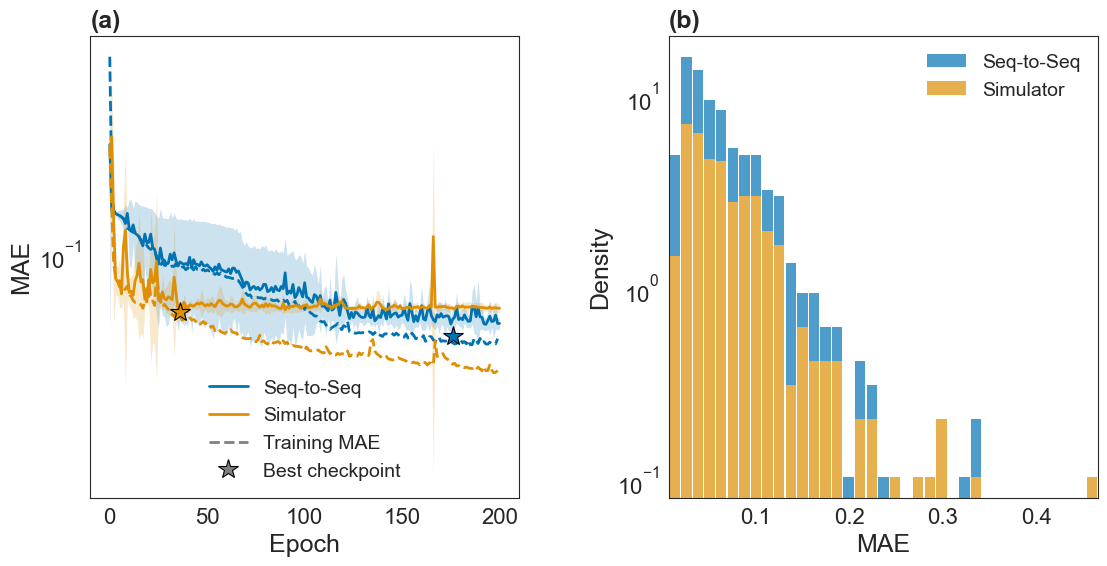

In [9]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)
sns.set_style("white")

# --- Left panel: validation MAE vs epoch (mean +/- std across folds) ---
ax1 = fig.add_subplot(gs[0])
hist_s2s = load_trial_history(experiment_path, metric="val_mae")
hist_sim = load_trial_history(experiment_path_sim, metric="val_mae")
hist_s2s_train = load_trial_history(experiment_path, metric="train_mae")
hist_sim_train = load_trial_history(experiment_path_sim, metric="train_mae")

for df_val, df_train, label, color in [
    (hist_s2s, hist_s2s_train, "Seq-to-Seq", palette[0]),
    (hist_sim, hist_sim_train, "Simulator", palette[1]),
]:
    ax1.plot(df_val["epoch"], df_val["mean"], label=label, color=color)
    ax1.fill_between(
        df_val["epoch"],
        df_val["mean"] - df_val["std"],
        df_val["mean"] + df_val["std"],
        color=color,
        alpha=0.2,
        linewidth=0,
    )
    # training MAE (mean across folds) as dashed line, same color
    ax1.plot(df_train["epoch"], df_train["mean"], color=color, linestyle="--")

# --- Star marker at the best checkpoint used for prediction ---
for exp_path, color in [
    (experiment_path, palette[0]),
    (experiment_path_sim, palette[1]),
]:
    best_epoch, best_val_mae = load_best_checkpoint_epoch(exp_path, optuna=True)
    ax1.plot(
        best_epoch, best_val_mae,
        marker="*", markersize=15, linestyle="None",
        color=color, markeredgecolor="black", markeredgewidth=0.8,
        zorder=5, clip_on=False,
    )

# legend proxies for the dashed training curves and the best-checkpoint star
ax1.plot([], [], color="gray", linestyle="--", label="Training MAE")
ax1.plot([], [], marker="*", markersize=15, linestyle="None", color="gray",
         markeredgecolor="black", markeredgewidth=0.8, label="Best checkpoint")

ax1.set_yscale("log")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MAE")
ax1.legend(frameon=False)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: MAE density ---
ax2 = fig.add_subplot(gs[1])
sns.histplot(
    data=df,
    x="MAE",
    hue="head",
    hue_order=["Seq-to-Seq", "Simulator"],
    edgecolor=None,
    alpha=0.7,
    linewidth=0,
    shrink=0.9,
    multiple="stack",
    legend=True,
    stat="density",
    ax=ax2
)
legend = ax2.get_legend()
if legend:
    legend.set_frame_on(False)
    legend.set_title(None)
ax2.set_yscale("log")
ax2.set_xlim(min(df["MAE"]), max(df["MAE"]))
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig1_val_mae_epoch_density.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

## Figure 2: Seq-to-Seq Predictions (Good vs Bad Samples)

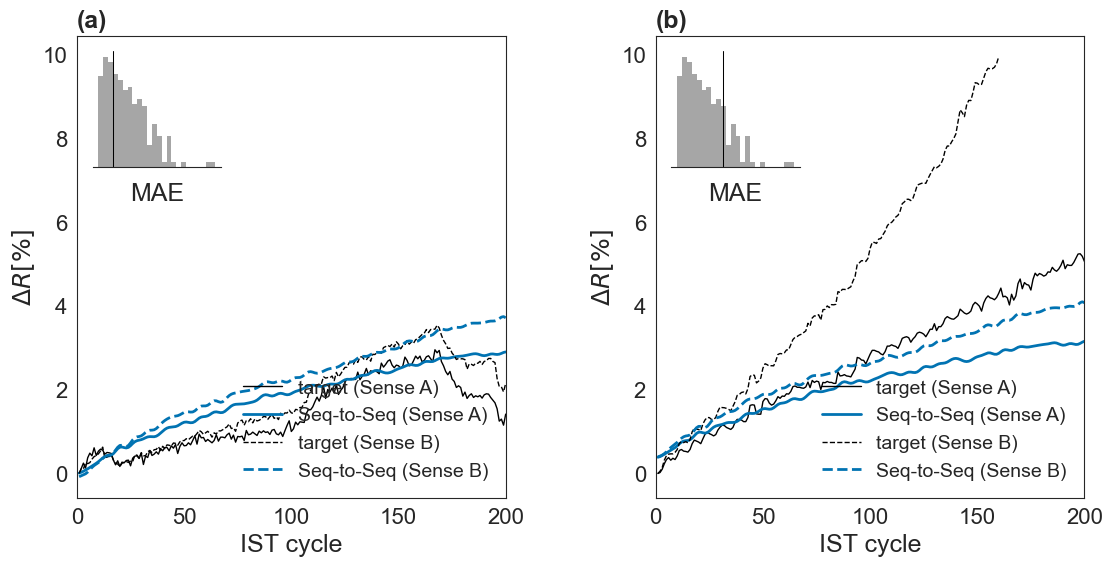

In [10]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Shared y-axis limits across panels (both Sense variables) ---
ylim_shared = shared_ylim(
    [good_idx, bad_idx], results,
    config.data.features.Y.variable, config.data.features.Y.value
)

# --- Left panel: good sample (lowest positive mean final value) ---
ax1 = fig.add_subplot(gs[0])
plot_predictions_enhanced(
    sample_id=good_idx,
    var_index=config.data.features.Y.variable,
    x_index=config.data.features.Y.position,
    val_index=config.data.features.Y.value,
    target_array=results.targets,
    output_array=[
        (results.outputs, "Seq-to-Seq"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_s2s,
    inset_position='upper left',
    legend_position='lower right',
    show_metrics_in_legend=False,
    ax=ax1,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Seq-to-Seq": palette[0]}
)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: bad sample (highest mean final value) ---
ax2 = fig.add_subplot(gs[1])
plot_predictions_enhanced(
    sample_id=bad_idx,
    var_index=config.data.features.Y.variable,
    x_index=config.data.features.Y.position,
    val_index=config.data.features.Y.value,
    target_array=results.targets,
    output_array=[
        (results.outputs, "Seq-to-Seq"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_s2s,
    inset_position='upper left',
    legend_position='lower right',
    show_metrics_in_legend=False,
    ax=ax2,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Seq-to-Seq": palette[0]}
)
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig2_seq2seq_good_bad.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

## Figure 3: Simulator Predictions (Same Good/Bad Samples)

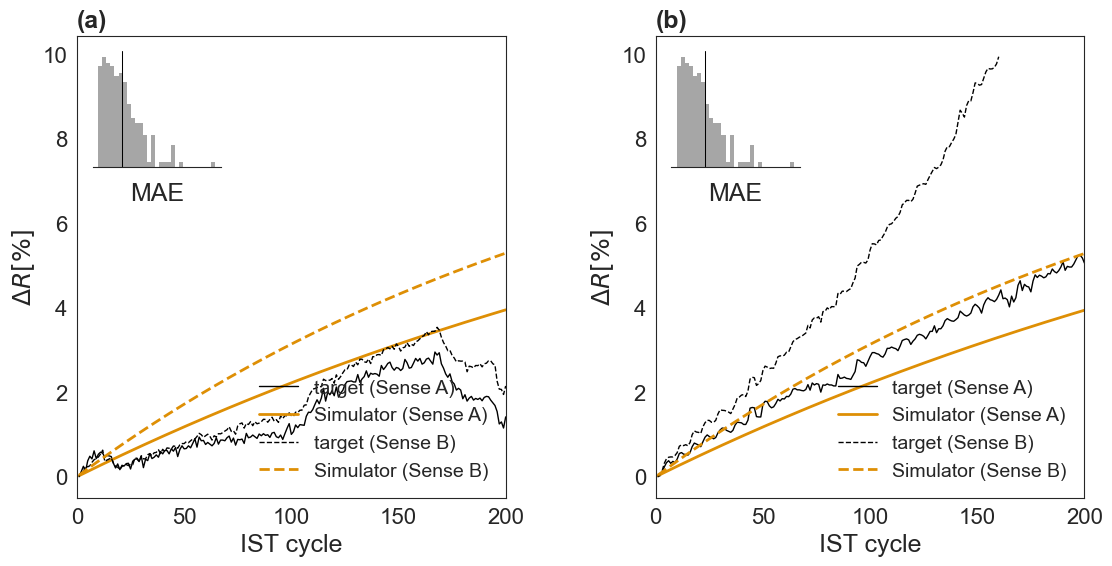

In [11]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Shared y-axis limits across panels (both Sense variables) ---
ylim_shared = shared_ylim(
    [good_idx, bad_idx], results_sim,
    config_sim.data.features.Y.variable, config_sim.data.features.Y.value
)

# --- Left panel: good sample (lowest positive mean final value) ---
ax1 = fig.add_subplot(gs[0])
plot_predictions_enhanced(
    sample_id=good_idx,
    var_index=config_sim.data.features.Y.variable,
    x_index=config_sim.data.features.Y.position,
    val_index=config_sim.data.features.Y.value,
    target_array=results_sim.targets,
    output_array=[
        (results_sim.outputs, "Simulator"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_sim,
    inset_position='upper left',
    legend_position='lower right',
    show_metrics_in_legend=False,
    ax=ax1,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Simulator": palette[1]}
)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: bad sample (highest mean final value) ---
ax2 = fig.add_subplot(gs[1])
plot_predictions_enhanced(
    sample_id=bad_idx,
    var_index=config_sim.data.features.Y.variable,
    x_index=config_sim.data.features.Y.position,
    val_index=config_sim.data.features.Y.value,
    target_array=results_sim.targets,
    output_array=[
        (results_sim.outputs, "Simulator"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_sim,
    inset_position='upper left',
    legend_position='lower right',
    show_metrics_in_legend=False,
    ax=ax2,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Simulator": palette[1]}
)
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig3_simulator_good_bad.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

## Rare Samples

In [12]:
df.sort_values("MAE", ascending=False)
rare_idx = 239

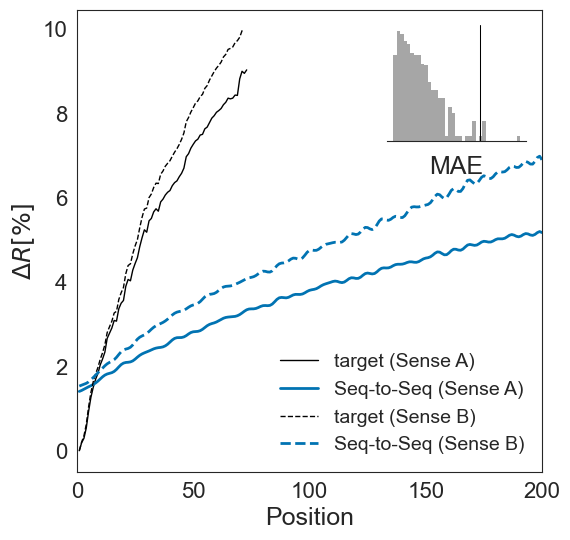

<Axes: xlabel='Position', ylabel='$\\Delta R [\\%]$'>

In [13]:
plot_predictions_enhanced(
    sample_id=rare_idx,
    var_index=config.data.features.Y.variable,
    x_index=config.data.features.Y.position,
    val_index=config.data.features.Y.value,
    target_array=results.targets,
    output_array=[
        (results.outputs, "Seq-to-Seq"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    mae_df=df_metrics,
    inset_position='upper right',
    legend_position='lower right',
    show_metrics_in_legend=False,
    save_dir=save_dir,
    tag="rare_sample"
)

In [14]:
experiment_path_sim     = r"../experiments/baseline_optuna/euler/baseline_proTCVRand_dyconex_sum_51972551"
config_adp, checkpoint_path_adp = get_config_and_best_checkpoint(experiment_path_sim)
rare_idx = 239

results_adp_10 = cached_prediction(
    "adaptive_10",
    lambda: predict_test_from_ckpt_adaptive(
        config_adp, 
        datadir_path, 
        checkpoint_path_adp,
        show_trg_max_idx=10,
    )
)

results_adp_50 = cached_prediction(
    "adaptive_50",
    lambda: predict_test_from_ckpt_adaptive(
        config_adp, 
        datadir_path, 
        checkpoint_path_adp,
        show_trg_max_idx=50,
    )
)

Loading cached predictions: ./output\case_study_adaptive_10.npz
Loading cached predictions: ./output\case_study_adaptive_50.npz


## Figure 4: Adaptive Predictions (10 vs 50)

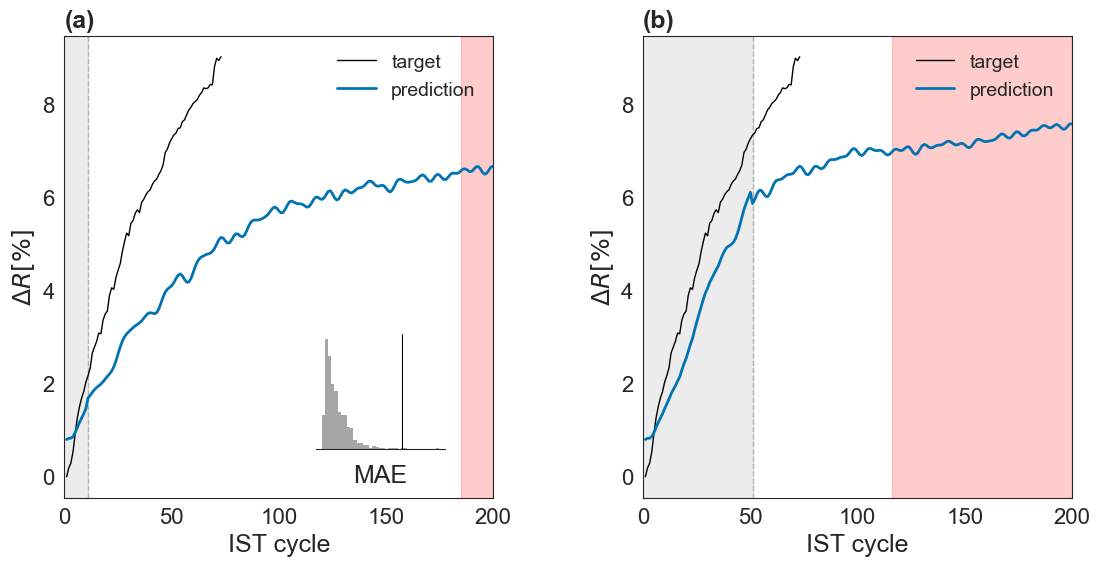

In [15]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)
config = config_adp


# --- Left panel: Adaptive prediction (show_trg_max_idx=10) ---
ax1 = fig.add_subplot(gs[0])
plot_predictions_adaptive(
    sample_id=rare_idx, 
    var_index=config.data.features.Y.variable, 
    x_index=config.data.features.Y.position, 
    val_index=config.data.features.Y.value, 
    target_array=results_adp_10.targets, 
    output_array=results_adp_10.outputs,
    selected_var=1,
    mae_df=df_metrics,
    inset_position='lower right',
    legend_position='upper right',
    show_metrics_in_legend=True,
    make_title=False,
    title_map=None, 
    show_failure=True,
    show_trg_max_idx=10,
    ax=ax1,
    show_inset=True,
)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: Adaptive prediction (show_trg_max_idx=50), no inset ---
ax2 = fig.add_subplot(gs[1])
plot_predictions_adaptive(
    sample_id=rare_idx, 
    var_index=config.data.features.Y.variable, 
    x_index=config.data.features.Y.position, 
    val_index=config.data.features.Y.value, 
    target_array=results_adp_50.targets, 
    output_array=results_adp_50.outputs,
    selected_var=1,
    mae_df=df_metrics,
    inset_position='lower right',
    legend_position='upper right',
    show_metrics_in_legend=True,
    make_title=False,
    title_map=None, 
    show_failure=True,
    show_trg_max_idx=50,
    ax=ax2,
    show_inset=False,
)
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_adaptive_predictions.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

C:\Users\ScipioneFrancesco\AppData\Local\Temp\ipykernel_34132\2755429000.py:42: RuntimeWarning: Mean of empty slice
  np.nanmean(x_vals, axis=0),
C:\Users\ScipioneFrancesco\AppData\Local\Temp\ipykernel_34132\2755429000.py:43: RuntimeWarning: Mean of empty slice
  np.nanmean(vals, axis=0),


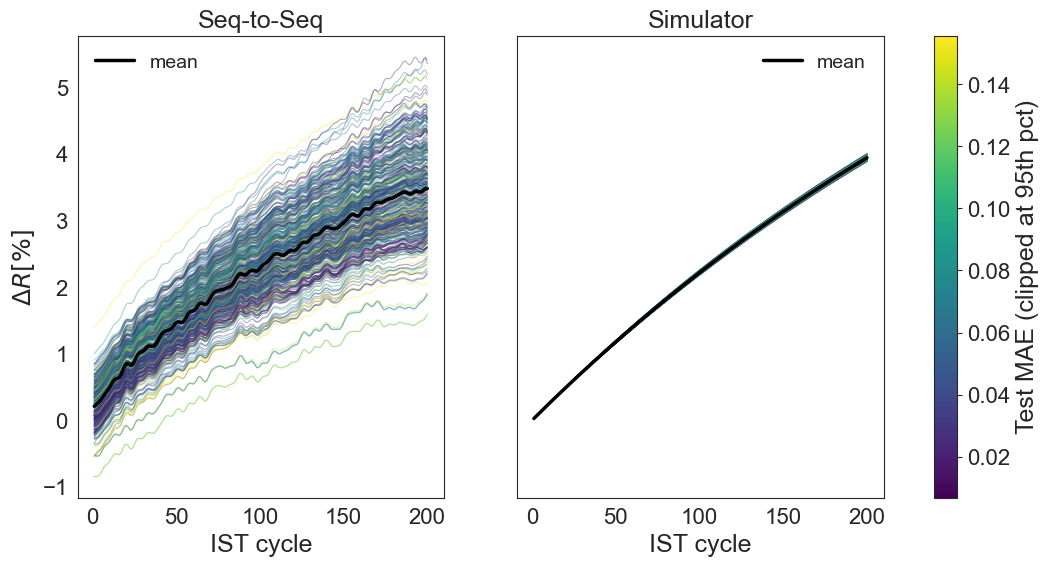

In [16]:
# --- All test predictions per model, curves colored by test MAE ---
# Note: use config_sim here because the adaptive cell above reassigns `config`.
sel_var = 1.0
var_idx = config_sim.data.features.Y.variable
x_idx = config_sim.data.features.Y.position

from matplotlib.colors import Normalize

# per-sample MAE aligned with the sample order of the prediction arrays
mae_per_head = {
    "Seq-to-Seq": df_s2s.set_index("index").sort_index()["MAE"].to_numpy(),
    "Simulator": df_sim.set_index("index").sort_index()["MAE"].to_numpy(),
}

# shared color scale across both panels, clipped at the 95th percentile (heavy tail)
cmap = plt.get_cmap("viridis")
mae_all = np.concatenate(list(mae_per_head.values()))
norm = Normalize(vmin=float(mae_all.min()), vmax=float(np.percentile(mae_all, 95)))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

for ax, (outputs, label) in zip(axes, [
    (results.outputs, "Seq-to-Seq"),
    (results_sim.outputs, "Simulator"),
]):
    value = outputs[:, :, 0] * 10 if outputs.ndim > 2 else outputs * 10
    var_mask = results.targets[:, :, var_idx] == sel_var  # (B, S)
    mae = mae_per_head[label]

    # individual sample curves, colored by test MAE
    for b in range(value.shape[0]):
        ax.plot(
            results.targets[b, :, x_idx][var_mask[b]],
            value[b][var_mask[b]],
            color=cmap(norm(mae[b])), alpha=0.4, linewidth=0.8,
        )

    # mean curve across samples
    vals = np.where(var_mask, value, np.nan)
    x_vals = np.where(var_mask, results.targets[:, :, x_idx], np.nan)
    ax.plot(
        np.nanmean(x_vals, axis=0),
        np.nanmean(vals, axis=0),
        color="black", linewidth=2.5, label="mean",
    )

    ax.set_title(label)
    ax.set_xlabel("IST cycle")
    ax.legend(frameon=False)

axes[0].set_ylabel(r"$\Delta R [\%]$")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=axes, label="Test MAE (clipped at 95th pct)")
plt.show()

## Long-Training Runs (2000 epochs)

Plain training runs (no optuna folder): the best-fold checkpoint is selected via `kfold_summary.json`.

Note: the simulator (2/5 folds) and adaptive (1/5 folds) runs are still in progress -
predictions and curves reflect the completed folds only. After re-copying the finished
runs, delete the matching `./output/case_study_*2000ep*.npz` caches to refresh predictions.

In [12]:
# select experiment
experiment_path_long = r"../experiments/training/proT_dyconex_2000ep_frozen_10299787"

config_long = OmegaConf.load(join(experiment_path_long, "config_proT_dyconex_2000ep.yaml"))
with open(join(experiment_path_long, "kfold_summary.json")) as f:
    kfold_summary_long = json.load(f)
best_fold_long = kfold_summary_long["best_fold"]["fold_number"]
checkpoint_path_long = join(experiment_path_long, f"k_{best_fold_long}", "checkpoints", "best_checkpoint.ckpt")
print(f"Best fold: {best_fold_long} -> {checkpoint_path_long}")

results_long = cached_prediction(
    "seq2seq_2000ep",
    lambda: predict_test_from_ckpt(
        config_long,
        datadir_path,
        checkpoint_path_long,
        None,
        dataset_label="test",
        cluster=False
        )
)

df_long = compute_prediction_metrics(results_long, target_feature_idx=config_long.data.features.Y.value)
df_long

Seed set to 42


Best fold: 3 -> ../experiments/training/proT_dyconex_2000ep_frozen_10299787\k_3\checkpoints\best_checkpoint.ckpt


c:\Users\ScipioneFrancesco\Documents\Projects\proT\myenv\Lib\site-packages\torch\__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:85.)
  _C._set_float32_matmul_precision(precision)


Decoder input embeddings frozen (freeze_dec_embedding=True)
Loading pre-split data.
Train input shape:  (1526, 1023, 12)
Train target shape:  (1526, 400, 9)
Test input shape:  (394, 1023, 12)
Test target shape:  (394, 400, 9)
Loading pre-split data.
Train input shape:  (1526, 1023, 12)
Train target shape:  (1526, 400, 9)
Test input shape:  (394, 1023, 12)
Test target shape:  (394, 400, 9)
Test dataset selected.
Predicting...


100%|██████████| 8/8 [00:07<00:00,  1.13it/s]


Cached predictions: ./output\case_study_seq2seq_2000ep.npz


,index,R2,MSE,MAE,RMSE
0,0,0.759728,0.007974,0.063180,0.089295
1,1,0.714116,0.003574,0.051422,0.059784
2,2,0.839879,0.002470,0.043988,0.049698
3,3,0.910113,0.001589,0.034213,0.039864
4,4,0.938325,0.001541,0.033815,0.039257
...,...,...,...,...,...
379,379,0.539412,0.006932,0.079918,0.083257
380,380,0.915563,0.002287,0.038993,0.047823
381,381,0.808855,0.003040,0.050037,0.055132
382,382,0.393669,0.004110,0.057214,0.064109


### Simulator (2000 epochs)

In [14]:
# select experiment
experiment_path_sim_long = r"../experiments/training/proTPhySim_dyconex_2000ep_10100925"

config_sim_long = OmegaConf.load(join(experiment_path_sim_long, "config_proTPhySim_dyconex_2000ep.yaml"))
with open(join(experiment_path_sim_long, "kfold_summary.json")) as f:
    kfold_summary_sim_long = json.load(f)
best_fold_sim_long = kfold_summary_sim_long["best_fold"]["fold_number"]
checkpoint_path_sim_long = join(experiment_path_sim_long, f"k_{best_fold_sim_long}", "checkpoints", "best_checkpoint.ckpt")
print(f"Best fold: {best_fold_sim_long} -> {checkpoint_path_sim_long}")

results_sim_long = cached_prediction(
    "sim_2000ep",
    lambda: predict_test_from_ckpt(
        config_sim_long,
        datadir_path,
        checkpoint_path_sim_long,
        None,
        dataset_label="test",
        cluster=False
        )
)

df_sim_long = compute_prediction_metrics(results_sim_long, target_feature_idx=config_sim_long.data.features.Y.value)

# combined metrics of the long runs (for density plot / insets)
df_metrics_long = pd.concat([
    df_long.assign(head="Seq-to-Seq"),
    df_sim_long.assign(head="Simulator"),
], axis=0)
df_sim_long

Best fold: 0 -> ../experiments/training/proTPhySim_dyconex_2000ep_10100925\k_0\checkpoints\best_checkpoint.ckpt
Loading cached predictions: ./output\case_study_sim_2000ep.npz


,index,R2,MSE,MAE,RMSE
0,0,0.707196,0.009717,0.083391,0.098575
1,1,0.822125,0.002224,0.043418,0.047157
2,2,0.791189,0.003221,0.051062,0.056754
3,3,0.959296,0.000720,0.023594,0.026826
4,4,0.791129,0.005219,0.065511,0.072244
...,...,...,...,...,...
379,379,0.947938,0.000784,0.024052,0.027992
380,380,0.659690,0.009217,0.091599,0.096007
381,381,0.916880,0.001322,0.029133,0.036356
382,382,-1.422101,0.016418,0.113020,0.128133


### Adaptive (2000 epochs)

In [15]:
# select experiment
experiment_path_adp_long = r"../experiments/training/proTCVRand_dyconex_2000ep_10103067"

config_adp_long = OmegaConf.load(join(experiment_path_adp_long, "config_proTCVRand_dyconex_2000ep.yaml"))
with open(join(experiment_path_adp_long, "kfold_summary.json")) as f:
    kfold_summary_adp_long = json.load(f)
best_fold_adp_long = kfold_summary_adp_long["best_fold"]["fold_number"]
checkpoint_path_adp_long = join(experiment_path_adp_long, f"k_{best_fold_adp_long}", "checkpoints", "best_checkpoint.ckpt")
print(f"Best fold: {best_fold_adp_long} -> {checkpoint_path_adp_long}")

results_adp_long_10 = cached_prediction(
    "adaptive_2000ep_10",
    lambda: predict_test_from_ckpt_adaptive(
        config_adp_long,
        datadir_path,
        checkpoint_path_adp_long,
        show_trg_max_idx=10,
    )
)

results_adp_long_50 = cached_prediction(
    "adaptive_2000ep_50",
    lambda: predict_test_from_ckpt_adaptive(
        config_adp_long,
        datadir_path,
        checkpoint_path_adp_long,
        show_trg_max_idx=50,
    )
)

Best fold: 0 -> ../experiments/training/proTCVRand_dyconex_2000ep_10103067\k_0\checkpoints\best_checkpoint.ckpt
Loading cached predictions: ./output\case_study_adaptive_2000ep_10.npz
Loading cached predictions: ./output\case_study_adaptive_2000ep_50.npz


### Figure L1: Validation MAE vs Epoch + MAE Density (2000 epochs)

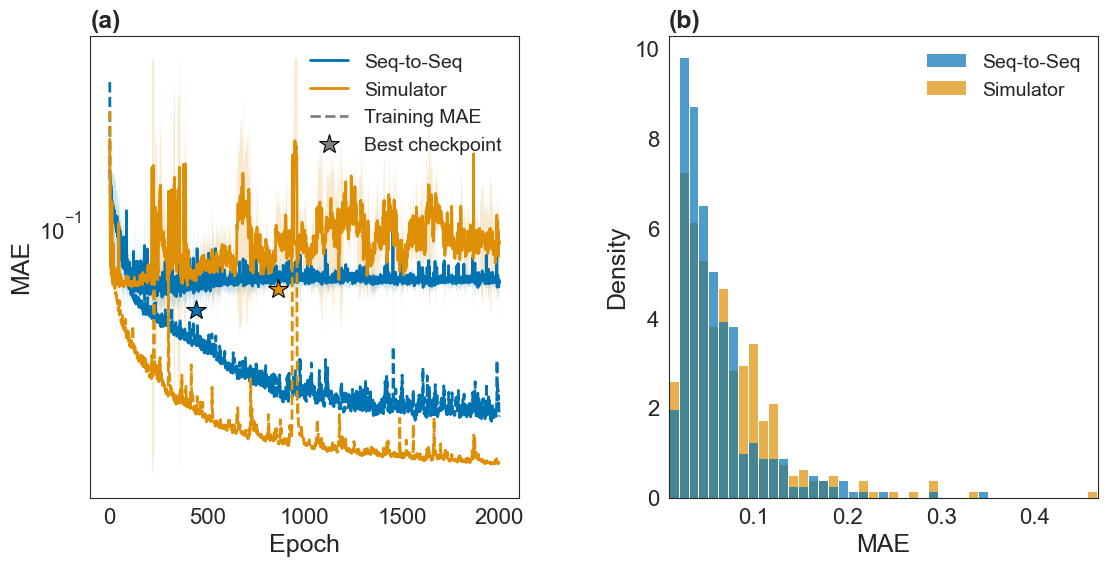

In [16]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Left panel: validation MAE vs epoch (mean +/- std across completed folds) ---
ax1 = fig.add_subplot(gs[0])
hist_s2s_long = load_run_history(experiment_path_long, metric="val_mae")
hist_sim_long = load_run_history(experiment_path_sim_long, metric="val_mae")
hist_adp_long = load_run_history(experiment_path_adp_long, metric="val_mae")
hist_s2s_long_train = load_run_history(experiment_path_long, metric="train_mae")
hist_sim_long_train = load_run_history(experiment_path_sim_long, metric="train_mae")

for df_val, df_train, label, color in [
    (hist_s2s_long, hist_s2s_long_train, "Seq-to-Seq", palette[0]),
    (hist_sim_long, hist_sim_long_train, "Simulator", palette[1]),
    #(hist_adp_long, "Adaptive (2000 ep)", palette[2]),
]:
    std = df_val["std"].fillna(0.0)  # single completed fold -> no band
    ax1.plot(df_val["epoch"], df_val["mean"], label=label, color=color)
    ax1.fill_between(
        df_val["epoch"],
        df_val["mean"] - std,
        df_val["mean"] + std,
        color=color,
        alpha=0.2,
        linewidth=0,
    )
    # training MAE (mean across folds) as dashed line, same color
    ax1.plot(df_train["epoch"], df_train["mean"], color=color, linestyle="--")

# --- Star marker at the best checkpoint used for prediction ---
for exp_path, color in [
    (experiment_path_long, palette[0]),
    (experiment_path_sim_long, palette[1]),
]:
    best_epoch, best_val_mae = load_best_checkpoint_epoch(exp_path, optuna=False)
    ax1.plot(
        best_epoch, best_val_mae,
        marker="*", markersize=15, linestyle="None",
        color=color, markeredgecolor="black", markeredgewidth=0.8,
        zorder=5, clip_on=False,
    )

# legend proxies for the dashed training curves and the best-checkpoint star
ax1.plot([], [], color="gray", linestyle="--", label="Training MAE")
ax1.plot([], [], marker="*", markersize=15, linestyle="None", color="gray",
         markeredgecolor="black", markeredgewidth=0.8, label="Best checkpoint")

ax1.set_yscale("log")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MAE")
ax1.legend(frameon=False)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: MAE density ---
ax2 = fig.add_subplot(gs[1])
sns.histplot(
    data=df_metrics_long,
    x="MAE",
    hue="head",
    hue_order=["Seq-to-Seq", "Simulator"],
    edgecolor=None,
    alpha=0.7,
    linewidth=0,
    shrink=0.9,
    #multiple="stack",
    legend=True,
    stat="density",
    ax=ax2,
    #bins=200
)
legend = ax2.get_legend()
if legend:
    legend.set_frame_on(False)
    legend.set_title(None)
#ax2.set_yscale("log")
ax2.set_xlim(min(df_metrics_long["MAE"]), max(df_metrics_long["MAE"]))
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_long_val_mae_epoch_density.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

In [17]:
print_percentile_candidates(
    results_long.targets, config_long.data.features.Y.variable, config_long.data.features.Y.value,
    percentiles=[0, 1, 2, 5, 10], positive_only=True, mae_df=df_s2s
)
print("\nHigh end:")
print_percentile_candidates(
    results_long.targets, config_long.data.features.Y.variable, config_long.data.features.Y.value,
    percentiles=[90, 95, 98, 99, 100], mae_df=df_s2s
)

   pct  index  final_value        MAE
   0.0     71       0.0138     0.3353
   1.0    166       0.1783     0.0482
   2.0    117       0.2255     0.0397
   5.0    167       0.2622     0.1291
  10.0     93       0.2958     0.0686

High end:
   pct  index  final_value        MAE
  90.0    214       0.6808     0.0904
  95.0    121       0.7501     0.1369
  98.0    326       0.8101     0.2198
  99.0    288       0.8545     0.1061
 100.0    239       0.9483     0.3204


In [18]:
# --- MANUAL SELECTION: edit these two ids after inspecting the candidate lists ---
good_idx = 117       
bad_idx = 121                     

print(f"\nSelected: good_idx={good_idx}, bad_idx={bad_idx}")


Selected: good_idx=117, bad_idx=121


In [19]:
# The long-run figures reuse the manually selected good_idx/bad_idx from the main
# selection cell (same test set and targets -> identical criterion values).
# Uncomment for an independent automatic pick instead:
# good_idx, _ = pick_final_value_sample(
#     results_long.targets, config_long.data.features.Y.variable, config_long.data.features.Y.value, mode="min"
# )
# bad_idx, _ = pick_final_value_sample(
#     results_long.targets, config_long.data.features.Y.variable, config_long.data.features.Y.value, mode="max"
# )
print(f"Using good_idx={good_idx}, bad_idx={bad_idx}")

Using good_idx=117, bad_idx=121


C:\Users\ScipioneFrancesco\AppData\Local\Temp\ipykernel_21452\103308119.py:41: RuntimeWarning: Mean of empty slice
  np.nanmean(x_vals, axis=0),
C:\Users\ScipioneFrancesco\AppData\Local\Temp\ipykernel_21452\103308119.py:42: RuntimeWarning: Mean of empty slice
  np.nanmean(vals, axis=0),


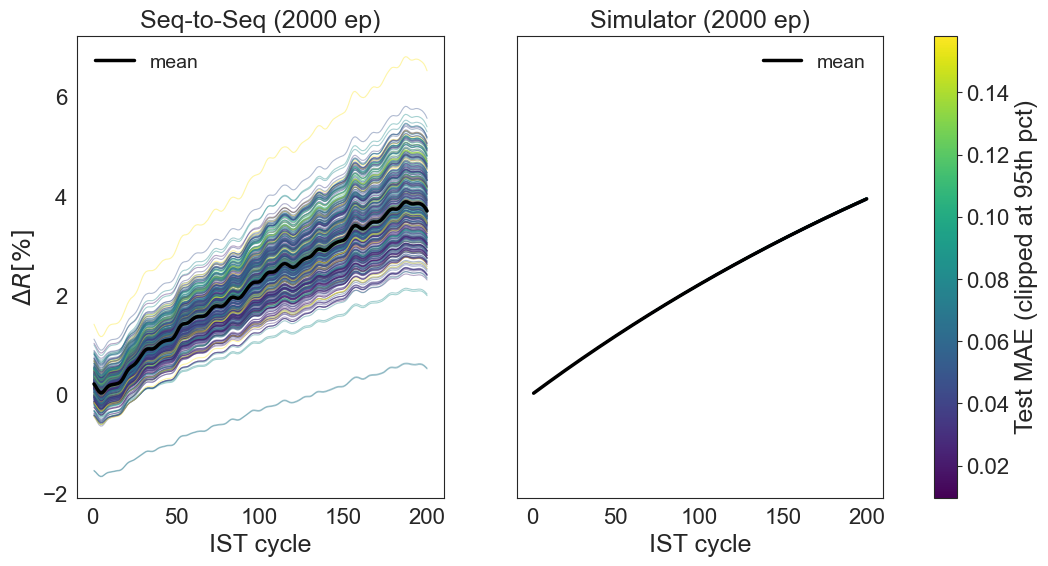

In [20]:
# --- All test predictions of the long-training runs, curves colored by test MAE ---
from matplotlib.colors import Normalize

sel_var = 1.0
var_idx = config_long.data.features.Y.variable
x_idx = config_long.data.features.Y.position

# per-sample MAE aligned with the sample order of the prediction arrays
mae_per_head_long = {
    "Seq-to-Seq (2000 ep)": df_long.set_index("index").sort_index()["MAE"].to_numpy(),
    "Simulator (2000 ep)": df_sim_long.set_index("index").sort_index()["MAE"].to_numpy(),
}

# shared color scale across both panels, clipped at the 95th percentile (heavy tail)
cmap = plt.get_cmap("viridis")
mae_all_long = np.concatenate(list(mae_per_head_long.values()))
norm = Normalize(vmin=float(mae_all_long.min()), vmax=float(np.percentile(mae_all_long, 95)))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

for ax, (res, label) in zip(axes, [
    (results_long, "Seq-to-Seq (2000 ep)"),
    (results_sim_long, "Simulator (2000 ep)"),
]):
    value = res.outputs[:, :, 0] * 10 if res.outputs.ndim > 2 else res.outputs * 10
    var_mask = res.targets[:, :, var_idx] == sel_var  # (B, S)
    mae = mae_per_head_long[label]

    # individual sample curves, colored by test MAE
    for b in range(value.shape[0]):
        ax.plot(
            res.targets[b, :, x_idx][var_mask[b]],
            value[b][var_mask[b]],
            color=cmap(norm(mae[b])), alpha=0.4, linewidth=0.8,
        )

    # mean curve across samples
    vals = np.where(var_mask, value, np.nan)
    x_vals = np.where(var_mask, res.targets[:, :, x_idx], np.nan)
    ax.plot(
        np.nanmean(x_vals, axis=0),
        np.nanmean(vals, axis=0),
        color="black", linewidth=2.5, label="mean",
    )

    ax.set_title(label)
    ax.set_xlabel("IST cycle")
    ax.legend(frameon=False)

axes[0].set_ylabel(r"$\Delta R [\%]$")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=axes, label="Test MAE (clipped at 95th pct)")
plt.show()

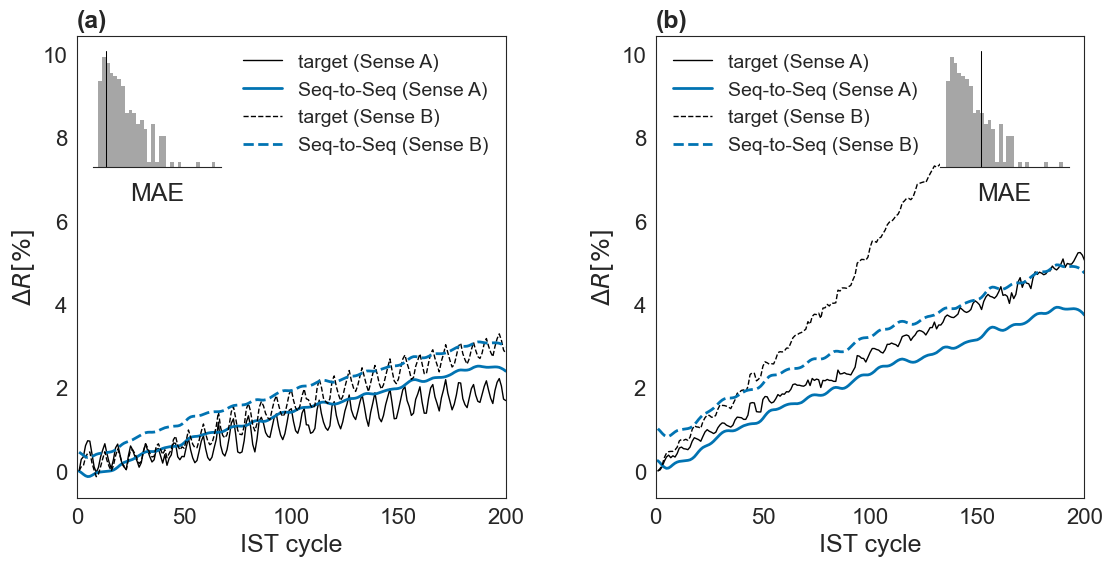

In [22]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Shared y-axis limits across panels (both Sense variables) ---
ylim_shared = shared_ylim(
    [good_idx, bad_idx], results_long,
    config_long.data.features.Y.variable, config_long.data.features.Y.value
)

# --- Left panel: good sample (lowest positive mean final value) ---
ax1 = fig.add_subplot(gs[0])
plot_predictions_enhanced(
    sample_id=good_idx,
    var_index=config_long.data.features.Y.variable,
    x_index=config_long.data.features.Y.position,
    val_index=config_long.data.features.Y.value,
    target_array=results_long.targets,
    output_array=[
        (results_long.outputs, "Seq-to-Seq"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_long,
    inset_position='upper left',
    legend_position='upper right',
    show_metrics_in_legend=False,
    ax=ax1,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Seq-to-Seq": palette[0]}
)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: bad sample (highest mean final value) ---
ax2 = fig.add_subplot(gs[1])
plot_predictions_enhanced(
    sample_id=bad_idx,
    var_index=config_long.data.features.Y.variable,
    x_index=config_long.data.features.Y.position,
    val_index=config_long.data.features.Y.value,
    target_array=results_long.targets,
    output_array=[
        (results_long.outputs, "Seq-to-Seq"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_long,
    inset_position='upper right',
    legend_position='upper left',
    show_metrics_in_legend=False,
    ax=ax2,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Seq-to-Seq": palette[0]}
)
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_long_seq2seq_good_bad.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

### Figure L3: Simulator Predictions (2000 epochs, Same Good/Bad Samples)

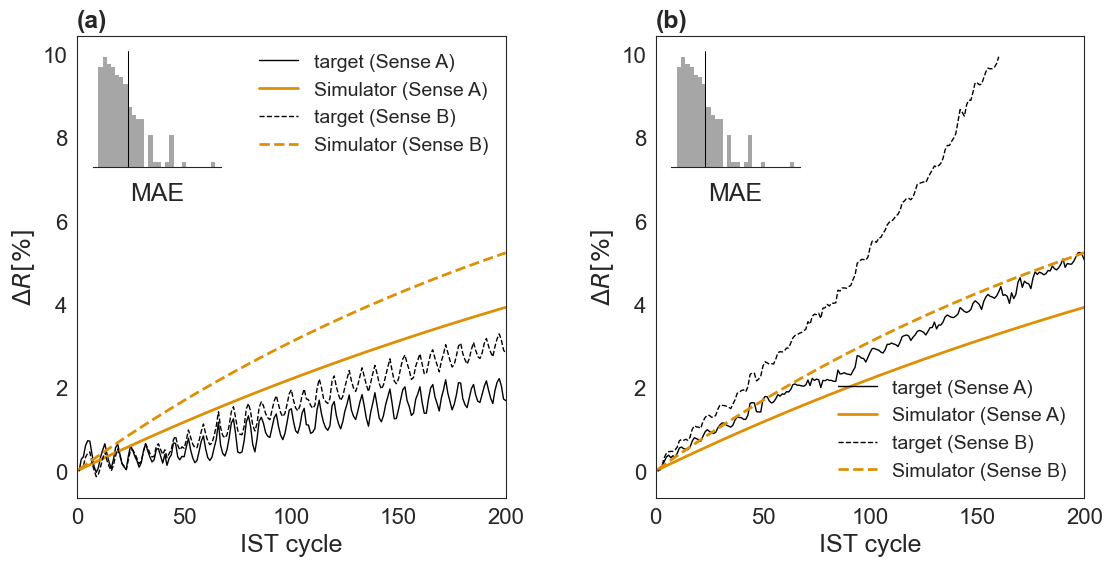

In [26]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Shared y-axis limits across panels (both Sense variables) ---
ylim_shared = shared_ylim(
    [good_idx, bad_idx], results_sim_long,
    config_sim_long.data.features.Y.variable, config_sim_long.data.features.Y.value
)

# --- Left panel: good sample (lowest positive mean final value) ---
ax1 = fig.add_subplot(gs[0])
plot_predictions_enhanced(
    sample_id=good_idx,
    var_index=config_sim_long.data.features.Y.variable,
    x_index=config_sim_long.data.features.Y.position,
    val_index=config_sim_long.data.features.Y.value,
    target_array=results_sim_long.targets,
    output_array=[
        (results_sim_long.outputs, "Simulator"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_sim_long,
    inset_position='upper left',
    legend_position='upper right',
    show_metrics_in_legend=False,
    ax=ax1,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Simulator": palette[1]}
)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: bad sample (highest mean final value) ---
ax2 = fig.add_subplot(gs[1])
plot_predictions_enhanced(
    sample_id=bad_idx,
    var_index=config_sim_long.data.features.Y.variable,
    x_index=config_sim_long.data.features.Y.position,
    val_index=config_sim_long.data.features.Y.value,
    target_array=results_sim_long.targets,
    output_array=[
        (results_sim_long.outputs, "Simulator"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    ylim=ylim_shared,
    mae_df=df_sim_long,
    inset_position='upper left',
    legend_position='lower right',
    show_metrics_in_legend=False,
    ax=ax2,
    show_inset=True,
    xlabel="IST cycle",
    color_map={"Simulator": palette[1]}
)
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_long_simulator_good_bad.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

### Simulator Physics Parameters (lam, beta)

The decoder input of proT_sim is a fixed scaffolding (4 tokens: Sense A/B x parameter slot),
so the 4 raw transformer outputs per sample ARE the physics parameters:
`lam = 1e-3 * softplus(raw)`, `beta = 1 + 10 * softplus(raw)` (DuctileIST).

Note: DuctileIST/FractureIST now use softplus instead of relu (see trajectory_simulator.py,
marked 'Here it was RELU'). The existing checkpoints were trained with relu.

✓ SimulatorForecaster initialized with model: D
✓ SimulatorForecaster initialized with model: D
model             signal   lam (mean +/- std)      beta (mean +/- std)     lam=0   beta=1  
Simulator 200 ep  Sense A  2.58e-03 +/- 2.02e-05   1.1116 +/- 0.0004        0.0%    0.0%
Simulator 200 ep  Sense B  3.78e-03 +/- 3.44e-05   1.1375 +/- 0.0011        0.0%    0.0%
Simulator 2000 ep Sense A  2.58e-03 +/- 7.54e-06   1.0130 +/- 0.0000        0.0%    0.0%
Simulator 2000 ep Sense B  3.75e-03 +/- 1.88e-05   1.0129 +/- 0.0000        0.0%    0.0%


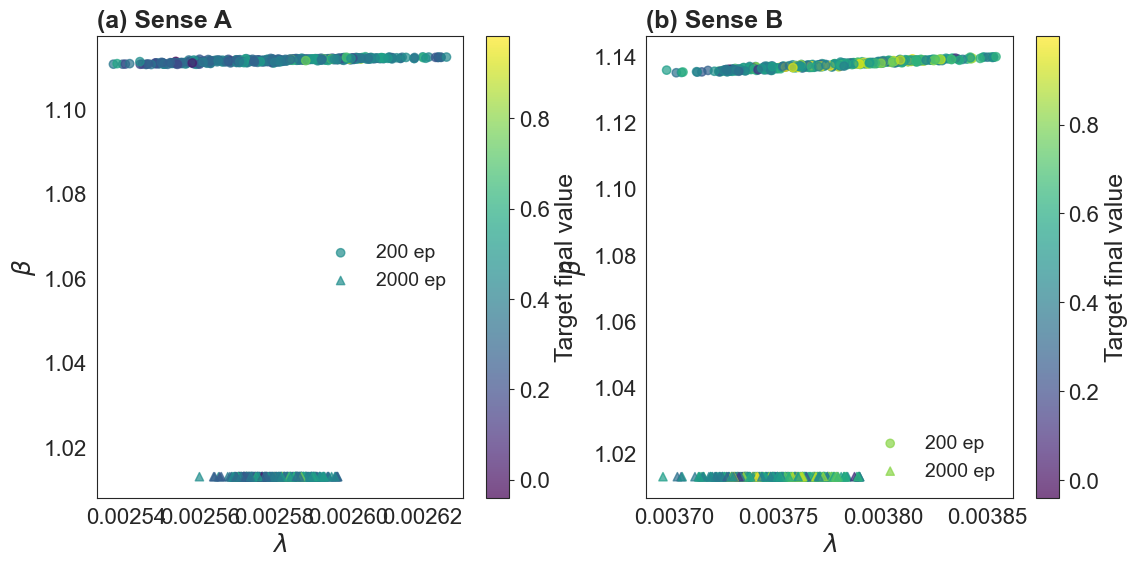

In [23]:
import torch
from proT.training.forecasters.simulator_forecaster import SimulatorForecaster

def predict_raw_sim_params(checkpoint_path, inputs, batch_size=64):
    """Raw transformer outputs (pre-simulator) of a proT_sim checkpoint. Returns (B, 4)."""
    forecaster = SimulatorForecaster.load_from_checkpoint(checkpoint_path)
    forecaster.eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    forecaster.to(device)
    raw = []
    with torch.no_grad():
        for i in range(0, len(inputs), batch_size):
            xb = torch.tensor(inputs[i:i + batch_size], dtype=torch.float32, device=device)
            dec_input = forecaster.decoder_input_module(batch_size=xb.size(0), device=device)
            model_output, _, _, _, _ = forecaster.model.forward(
                input_tensor=xb, target_tensor=dec_input, trg_pos_mask=None
            )
            raw.append(model_output.cpu().numpy())
    return np.concatenate(raw)[:, :, 0]  # (B, 4): raw [lam_A, beta_A, lam_B, beta_B] slots

def to_physics(raw):
    """Map raw slots to (lam, beta) per signal, as in DuctileIST.forward (softplus)."""
    sp = lambda x: np.logaddexp(0, x)  # numerically stable softplus
    return {
        "Sense A": (1e-3 * sp(raw[:, 0]), 1.0 + 10.0 * sp(raw[:, 1])),
        "Sense B": (1e-3 * sp(raw[:, 2]), 1.0 + 10.0 * sp(raw[:, 3])),
    }

raw_200 = predict_raw_sim_params(checkpoint_path_sim, results_sim.inputs)
raw_2000 = predict_raw_sim_params(checkpoint_path_sim_long, results_sim_long.inputs)
params_200, params_2000 = to_physics(raw_200), to_physics(raw_2000)

# per-signal target final value (for coloring)
fval = {
    sig: final_value_table(
        results_sim.targets,
        config_sim.data.features.Y.variable,
        config_sim.data.features.Y.value,
        selected_vars=(v,),
    )["final_value"].to_numpy()
    for sig, v in [("Sense A", 1.0), ("Sense B", 2.0)]
}

# --- summary table ---
print(f"{'model':<18}{'signal':<9}{'lam (mean +/- std)':<24}{'beta (mean +/- std)':<24}{'lam=0':<8}{'beta=1':<8}")
for name, params in [("Simulator 200 ep", params_200), ("Simulator 2000 ep", params_2000)]:
    for sig, (lam, beta) in params.items():
        print(f"{name:<18}{sig:<9}{lam.mean():.2e} +/- {lam.std():.2e}   "
              f"{beta.mean():.4f} +/- {beta.std():.4f}      "
              f"{(lam == 0).mean() * 100:5.1f}%  {(beta == 1.0).mean() * 100:5.1f}%")

# --- scatter lam vs beta per signal, colored by target final value ---
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, sig, panel in zip(axes, ["Sense A", "Sense B"], ["(a)", "(b)"]):
    lam200, beta200 = params_200[sig]
    lam2000, beta2000 = params_2000[sig]
    sc = ax.scatter(lam200, beta200, c=fval[sig], cmap="viridis", marker="o", alpha=0.7, label="200 ep")
    ax.scatter(lam2000, beta2000, c=fval[sig], cmap="viridis", marker="^", alpha=0.7, label="2000 ep")
    ax.set_xlabel(r"$\lambda$")
    ax.set_ylabel(r"$\beta$")
    ax.set_title(f"{panel} {sig}", loc="left", fontweight="bold")
    ax.legend(frameon=False)
    fig.colorbar(sc, ax=ax, label="Target final value")

for fmt in ["pdf", "svg", "png"]:
    fig.savefig(join(save_dir, f"fig_sim_physics_params.{fmt}"), format=fmt, bbox_inches="tight", dpi=360)
plt.show()

### Rare Sample (2000 epochs)

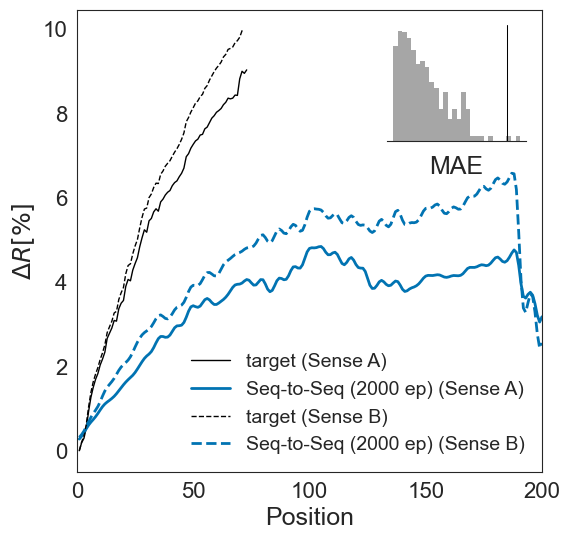

<Axes: xlabel='Position', ylabel='$\\Delta R [\\%]$'>

In [28]:
plot_predictions_enhanced(
    sample_id=rare_idx,
    var_index=config_long.data.features.Y.variable,
    x_index=config_long.data.features.Y.position,
    val_index=config_long.data.features.Y.value,
    target_array=results_long.targets,
    output_array=[
        (results_long.outputs, "Seq-to-Seq (2000 ep)"),
    ],
    selected_var=1.0,
    selected_var2=2.0,
    mae_df=df_long,
    inset_position='upper right',
    legend_position='lower right',
    show_metrics_in_legend=False,
    save_dir=save_dir,
    tag="rare_sample_2000ep"
)

### Figure L4: Adaptive Predictions (10 vs 50, 2000 epochs)

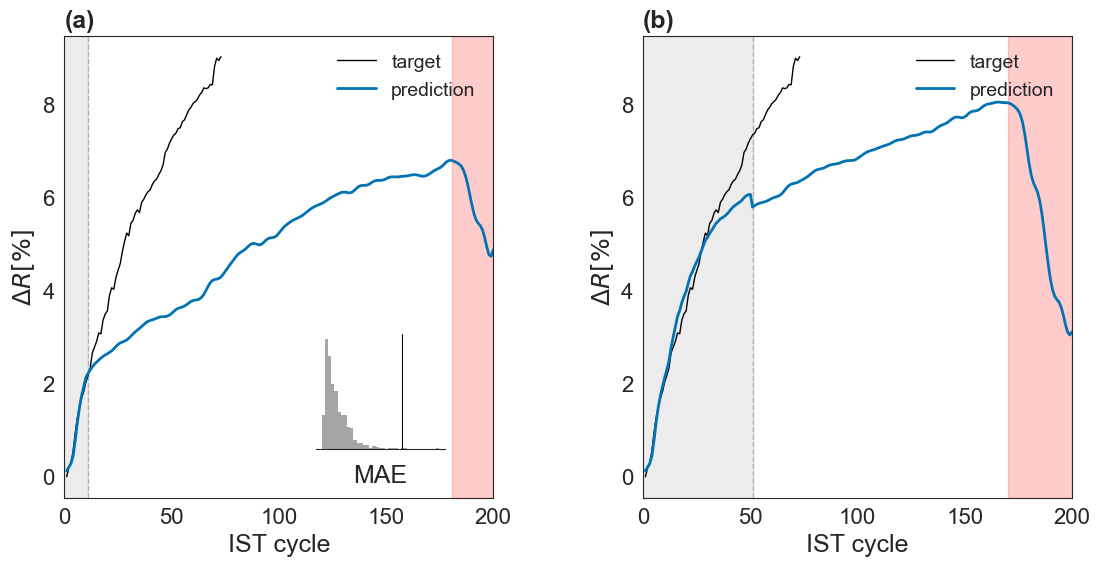

In [29]:
# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Left panel: Adaptive prediction (show_trg_max_idx=10) ---
ax1 = fig.add_subplot(gs[0])
plot_predictions_adaptive(
    sample_id=rare_idx, 
    var_index=config_adp_long.data.features.Y.variable, 
    x_index=config_adp_long.data.features.Y.position, 
    val_index=config_adp_long.data.features.Y.value, 
    target_array=results_adp_long_10.targets, 
    output_array=results_adp_long_10.outputs,
    selected_var=1,
    mae_df=df_metrics,
    inset_position='lower right',
    legend_position='upper right',
    show_metrics_in_legend=True,
    make_title=False,
    title_map=None, 
    show_failure=True,
    show_trg_max_idx=10,
    ax=ax1,
    show_inset=True,
)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: Adaptive prediction (show_trg_max_idx=50), no inset ---
ax2 = fig.add_subplot(gs[1])
plot_predictions_adaptive(
    sample_id=rare_idx, 
    var_index=config_adp_long.data.features.Y.variable, 
    x_index=config_adp_long.data.features.Y.position, 
    val_index=config_adp_long.data.features.Y.value, 
    target_array=results_adp_long_50.targets, 
    output_array=results_adp_long_50.outputs,
    selected_var=1,
    mae_df=df_metrics,
    inset_position='lower right',
    legend_position='upper right',
    show_metrics_in_legend=True,
    make_title=False,
    title_map=None, 
    show_failure=True,
    show_trg_max_idx=50,
    ax=ax2,
    show_inset=False,
)
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_long_adaptive_predictions.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()